Poisson-Kac process - Vibe Coders - Notebook

Task 1

Calculated term for mu: 10.0


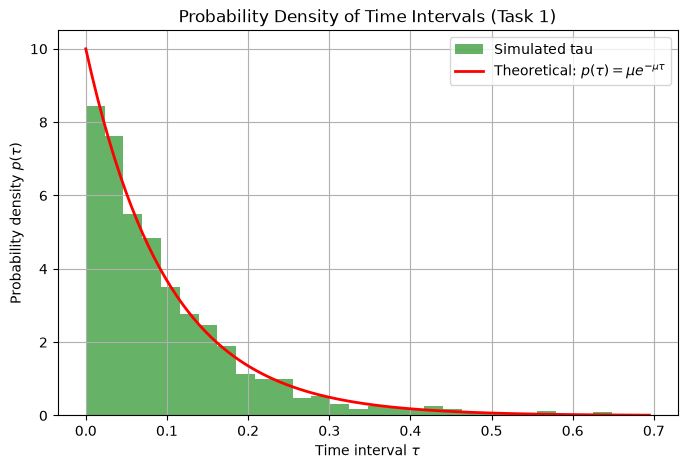

In [2]:
import matplotlib.pyplot as plt
import numpy as np
rng = np.random.default_rng()



def generate_poisson_intervals(N,T):
    t_events=np.sort(rng.uniform(0, T, N))
    tau = np.diff(t_events)
    return tau

def main_function():
    N = 1000
    T = 100

    tau = generate_poisson_intervals(N, T)

    mu = N/T
    print(f"Calculated term for mu: {mu}")

    plt.figure(figsize=(8,5))
    plt.hist(tau, bins=30, density=True, alpha=0.6, color='g', label='Simulated tau')

    tau_theoretical = np.linspace(0, np.max(tau), 100)
    p_tau = mu * np.exp(-mu * tau_theoretical)
    plt.plot(tau_theoretical, p_tau, "r-", linewidth=2, label=r"Theoretical: $p(\tau) = \mu e^{-\mu\tau}$",
    )

    plt.title("Probability Density of Time Intervals (Task 1)")
    plt.xlabel(r"Time interval $\tau$")
    plt.ylabel(r"Probability density $p(\tau)$")
    plt.legend()
    plt.grid(True)
    #plt.savefig("images/task1_distribution_Elia.png")
    plt.show()


main_function()

Task 2

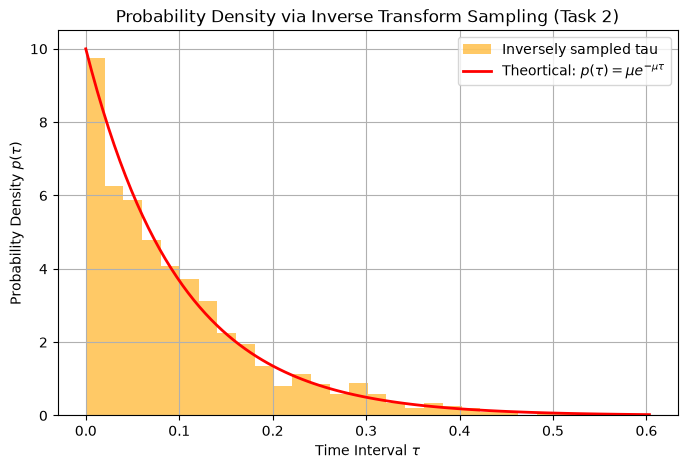

In [3]:
import matplotlib.pyplot as plt
import numpy as np

rng=np.random.default_rng()

def generate_inverse_exponential(N, mu):
    P = rng.uniform(0, 1, N)
    tau = -np.log(1-P) / mu
    return tau

def main_function():
    N = 1000
    T = 100
    mu = N / T
    tau = generate_inverse_exponential(N, mu)

    plt.figure(figsize=(8, 5))
    plt.hist(tau, bins=30, density=True, alpha=0.6, color='orange', label='Inversely sampled tau')

    tau_theoretical = np.linspace(0,np.max(tau), 100)
    p_tau = mu * np.exp(-mu * tau_theoretical)
    plt.plot(tau_theoretical, p_tau, "r-", linewidth=2, label=r"Theortical: $p(\tau) = \mu e^{-\mu\tau}$")

    plt.xlabel(r'Time Interval $\tau$')
    plt.ylabel(r'Probability Density $p(\tau)$')
    plt.title('Probability Density via Inverse Transform Sampling (Task 2)')
    plt.legend()
    plt.grid(True)
    #plt.savefig("images/task2_distribution_Elia.png")
    plt.show()

main_function()

Task 3

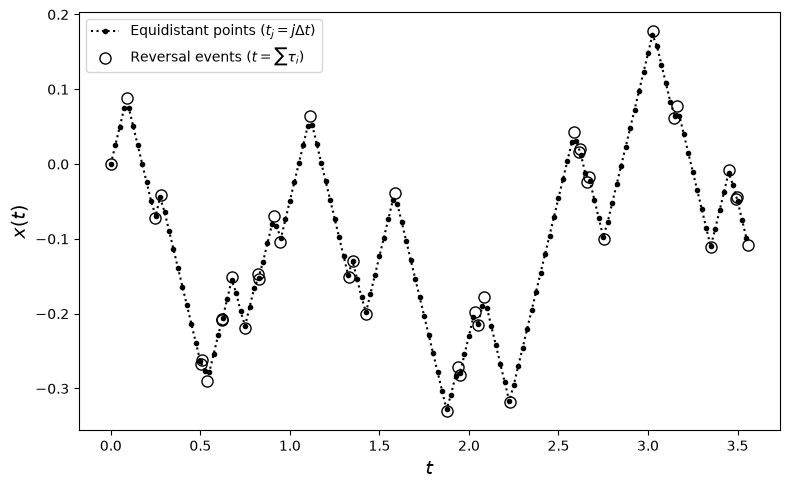

In [4]:
import numpy as np
import matplotlib.pyplot as plt

def generate_event_trajectory(N, rate_mu, speed_s):
    P = np.random.uniform(0, 1, N)
    tau = -np.log(1.0 - P) / rate_mu
  
    t_events = np.zeros(N + 1)
    x_events = np.zeros(N + 1)
    
    current_v = speed_s
    for i in range(N):
        t_events[i + 1] = t_events[i] + tau[i]
        x_events[i + 1] = x_events[i] + current_v * tau[i]
        current_v = -current_v  # Geschwindigkeitsumkehr
        
    return t_events, x_events

def interpolate_equidistant_trajectory(t_events, x_events, speed_s, dt):
    # Erstellt die Trajektorie an äquidistanten Zeitpunkten t_j = j * dt
    t_max = t_events[-1]
    t_grid = np.arange(0, t_max, dt)
    x_grid = np.zeros_like(t_grid)
    
    # Für jeden Zeitpunkt t_j wird die exakte Position durch Stückweise Linearität berechnet
    for j, t in enumerate(t_grid):
        # Finde das Intervall, in dem t liegt
        idx = np.searchsorted(t_events, t, side='right') - 1
        if idx < len(t_events) - 1:
            # Vorzeichen der Geschwindigkeit bestimmen: alternierend (+s, -s, +s, ...)
            v_current = speed_s if (idx % 2 == 0) else -speed_s
            x_grid[j] = x_events[idx] + v_current * (t - t_events[idx])
        else:
            x_grid[j] = x_events[-1]
            
    return t_grid, x_grid

def main_function():
    N = 40
    rate_mu = 10
    speed_s = 1
    dt = 0.25 / rate_mu

    # Event-basierte Trajektorie
    t_events, x_events = generate_event_trajectory(N, rate_mu, speed_s)
    
    # Äquidistante Trajektorie
    t_grid, x_grid = interpolate_equidistant_trajectory(t_events, x_events, speed_s, dt)
    
    # Visualisierung
    plt.figure(figsize=(8, 5))
    
    # Zeichne äquidistante Punkte und gestrichelte Verbindungslinie
    plt.plot(t_grid, x_grid, 'k:.', label='Equidistant points ($t_j = j \\Delta t$)')
    
    # Zeichne Event-Kreise
    plt.plot(t_events, x_events, 'ko', mfc='none', ms=8, label='Reversal events ($t = \\sum \\tau_i$)')
    
    plt.xlabel('$t$', fontsize=14)
    plt.ylabel('$x(t)$', fontsize=14)
    plt.grid(False)
    plt.legend()
    plt.tight_layout()
    #plt.savefig('images/task3_trajectory_Elia.png')
    plt.show()

main_function()

Task 4

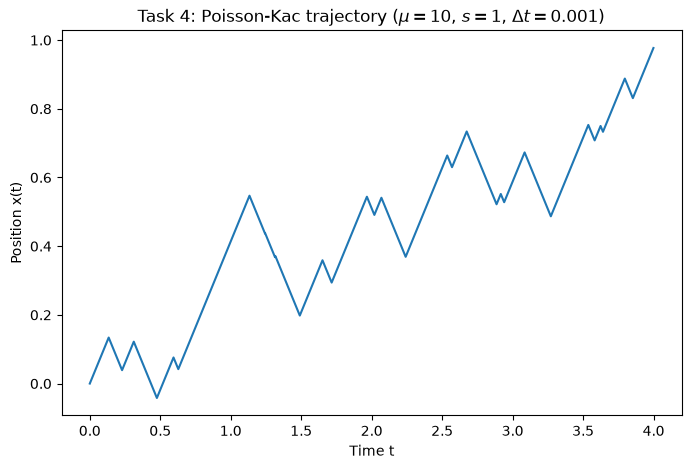

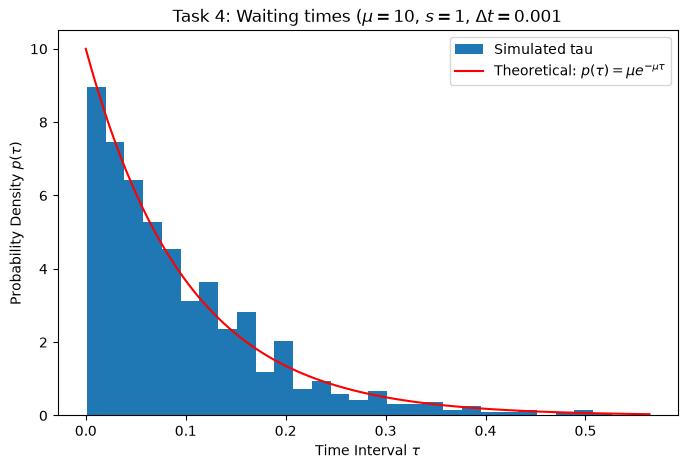

In [5]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng()

mu = 10
s = 1
dt = 0.01/mu
n_steps = 100000

v = s
x = 0
x_values = [x]
flip_steps = []

f = 1 - np.exp(-mu * dt)

for steps in range(1, n_steps + 1):
    x = x + v * dt
    x_values.append(x)
    
    r = rng.uniform(0, 1)

    if r < f:
        v = -v
        flip_steps.append(steps)

#print(len(x_values))
#print(len(flip_steps))

t_values = np.arange(len(x_values)) * dt

plt.figure(figsize=(8, 5))
plt.plot(t_values[:4000], x_values[:4000])
plt.xlabel("Time t")
plt.ylabel("Position x(t)")
plt.title(rf"Task 4: Poisson-Kac trajectory ($\mu={mu}$, $s={s}$, $\Delta t={dt}$)")
#plt.savefig('images/task4_poisson-kac-trajectory_Nicola.png')
plt.show()

tau = np.diff(flip_steps) * dt
tau_theoretical = np.linspace(0,np.max(tau), 100)
tau_theoretical_curve = mu * np.exp(-mu * tau_theoretical)

plt.figure(figsize=(8, 5))
plt.hist(tau, bins = 30, density = True, label='Simulated tau')
plt.plot(tau_theoretical, tau_theoretical_curve, "r-", label=r"Theoretical: $p(\tau) = \mu e^{-\mu\tau}$")
plt.xlabel(r'Time Interval $\tau$')
plt.ylabel(r'Probability Density $p(\tau)$')
plt.title(rf"Task 4: Waiting times ($\mu={mu}$, $s={s}$, $\Delta t={dt}$")
plt.legend()
#plt.savefig('images/task4_waiting_times_Nicola.png')
plt.show()



Task 5

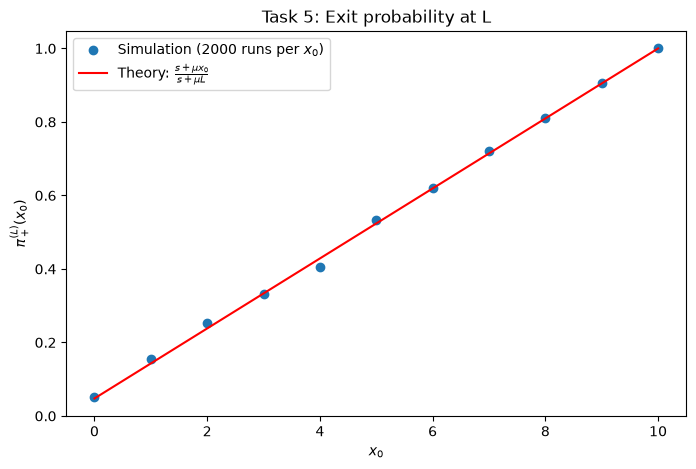

In [6]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng()

mu = 2
s = 1
dt = 0.01/mu
L = 10
repetitions = 2000
#x0 = 5

f = 1 - np.exp(-mu * dt)

def probability_exit(x0):
    touched_0 = []
    touched_L = []

    for n_simulations in range(repetitions):
        x = x0
        v = s

        while True:
            x = x + v * dt

            if x <= 0:
                touched_0.append(1)
                #print("touched 0 at:", steps)
                break

            elif x >= L:
                touched_L.append(1)
                #print("touched L at:", steps)
                break

            r = rng.uniform(0, 1)

            if r < f:
                v = -v

    return len(touched_L) / repetitions

x0_values = np.linspace(0, L, 11)
pi_plus_L = np.array([probability_exit(x0) for x0 in x0_values])
theory = (s + mu * x0_values) / (s + mu * L)

#print(pi_plus_L)

plt.figure(figsize=(8, 5))
plt.plot(x0_values, pi_plus_L, 'o', label=rf'Simulation ({repetitions} runs per $x_0$)')
plt.plot(x0_values, theory, 'r-', label=r'Theory: $\frac{s+\mu x_0}{s+\mu L}$')
plt.title(rf'Task 5: Exit probability at $x=L$ ($L={L}$, $\mu={mu}$, $s={s}$, $\Delta t={dt}$)')
plt.xlabel(r'$x_0$')
plt.ylabel(r'$\pi_+^{(L)}(x_0)$')
plt.title('Task 5: Exit probability at L')
plt.legend()
#plt.savefig('images/task5_exit_probability_Nicola.png', dpi=300)
plt.show()




Task 6

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng()

mu = 2
s = 1
dt = 0.01/mu
L = 10
quick_test = True      # True: 1/4 of the repetitions, for a fast check
repetitions = 2000 // 4 if quick_test else 2000

f = 1 - np.exp(-mu * dt)

def exit_statistics(x0, v0):
    # returns mean residence time T and exit probability at L for start (x0, v0)
    times = []
    touched_L = []

    for n_simulations in range(repetitions):
        x = x0
        v = v0
        steps = 0

        while True:
            x = x + v * dt
            steps += 1

            if x <= 0:
                touched_L.append(0)
                break

            elif x >= L:
                touched_L.append(1)
                break

            r = rng.uniform(0, 1)

            if r < f:
                v = -v

        times.append(steps * dt)

    return np.mean(times), np.mean(touched_L)

x0_values = np.linspace(0, L, 11)

T_plus = np.zeros(len(x0_values))
T_minus = np.zeros(len(x0_values))
pi_plus_L = np.zeros(len(x0_values))
pi_minus_L = np.zeros(len(x0_values))

for i in range(len(x0_values)):
    x0 = x0_values[i]
    T_plus[i], pi_plus_L[i] = exit_statistics(x0, s)
    T_minus[i], pi_minus_L[i] = exit_statistics(x0, -s)

# Part 1: mean residence time
T_mean = (T_plus + T_minus) / 2
T_theory = L / (2*s) + mu * x0_values * (L - x0_values) / s**2

plt.figure(figsize=(8, 5))
plt.plot(x0_values, T_mean, 'o', label=rf'Simulation ({repetitions} runs per $x_0$)')
plt.plot(x0_values, T_theory, 'r-', label=r'Theory: $\frac{L}{2s}+\frac{\mu x_0(L-x_0)}{s^2}$')
plt.xlabel(r'$x_0$')
plt.ylabel(r'$[T_+(x_0)+T_-(x_0)]/2$')
plt.title(rf'Task 6: Mean residence time ($L={L}$, $\mu={mu}$, $s={s}$, $\Delta t={dt}$)')
plt.legend()
#plt.savefig('images/task6_residence_time_Nicola.png', dpi=300)
plt.show()

# Part 2: exit probability relation
lhs = (pi_plus_L + pi_minus_L) / 2 * L - x0_values
lhs_theory = s * (L - 2*x0_values) / (2 * (s + mu*L))

plt.figure(figsize=(8, 5))
plt.plot(x0_values, lhs, 'o', label=rf'Simulation ({repetitions} runs per $x_0$)')
plt.plot(x0_values, lhs_theory, 'r-', label=r'Theory: $\frac{s(L-2x_0)}{2(s+\mu L)}$')
plt.xlabel(r'$x_0$')
plt.ylabel(r'$[\pi_+^{(L)}(x_0)+\pi_-^{(L)}(x_0)]\,L/2-x_0$')
plt.title(rf'Task 6: Exit probability relation ($L={L}$, $\mu={mu}$, $s={s}$, $\Delta t={dt}$)')
plt.legend()
#plt.savefig('images/task6_exit_probability_relation_Nicola.png', dpi=300)
plt.show()
